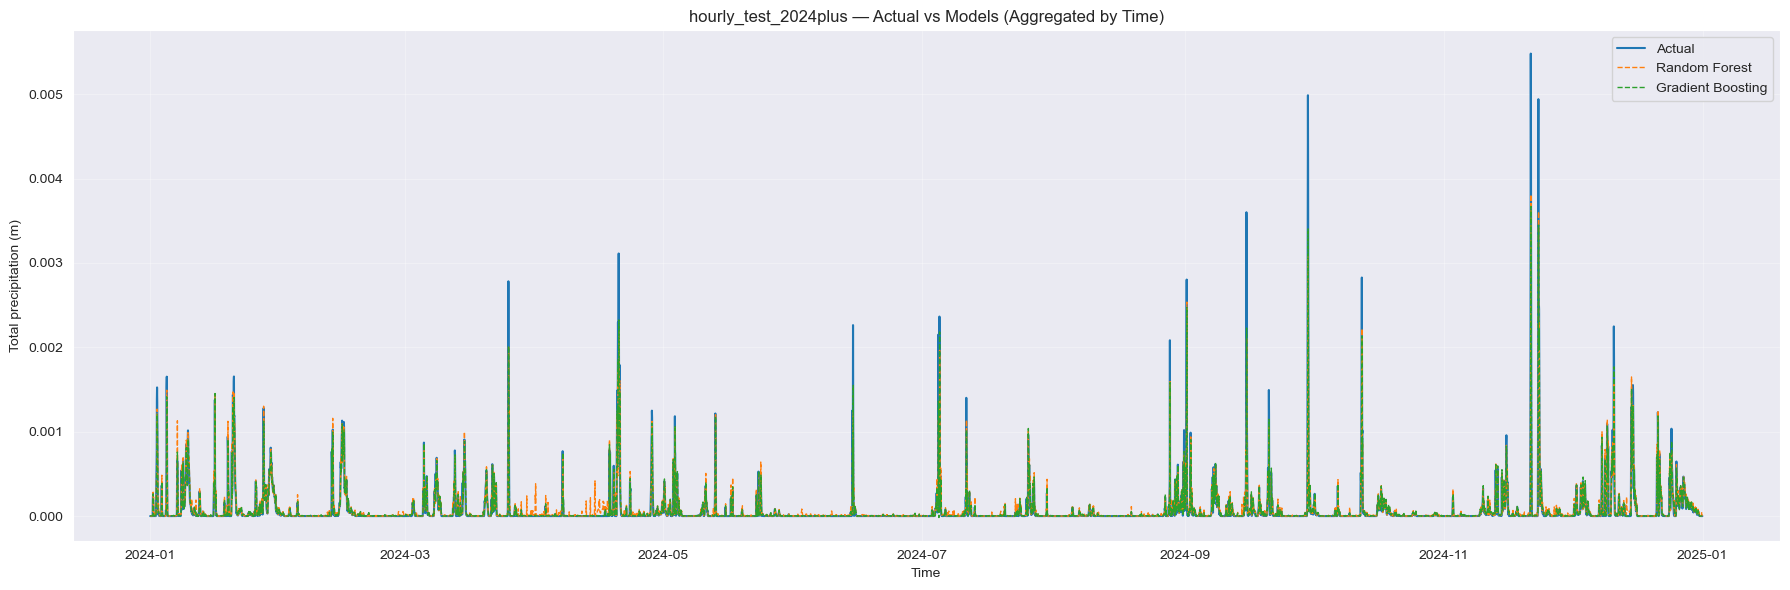

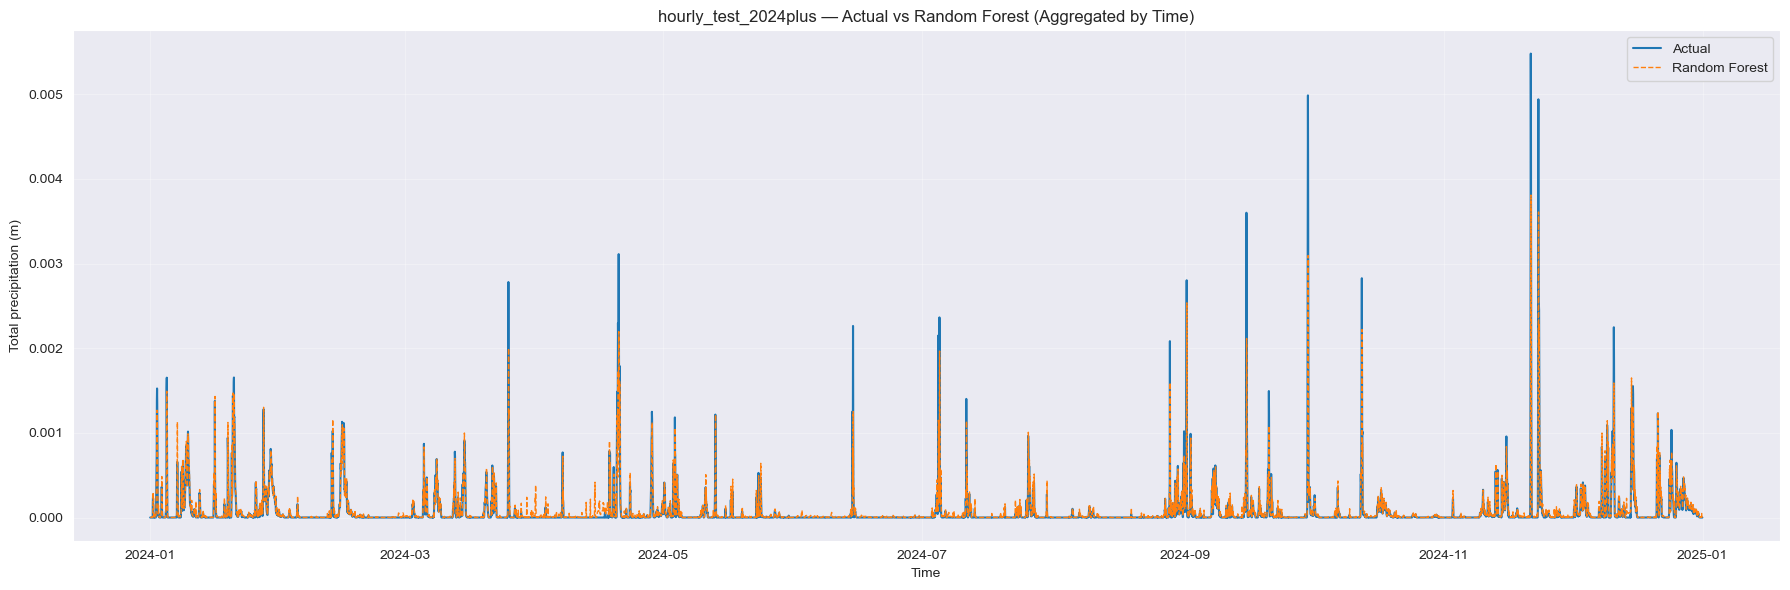

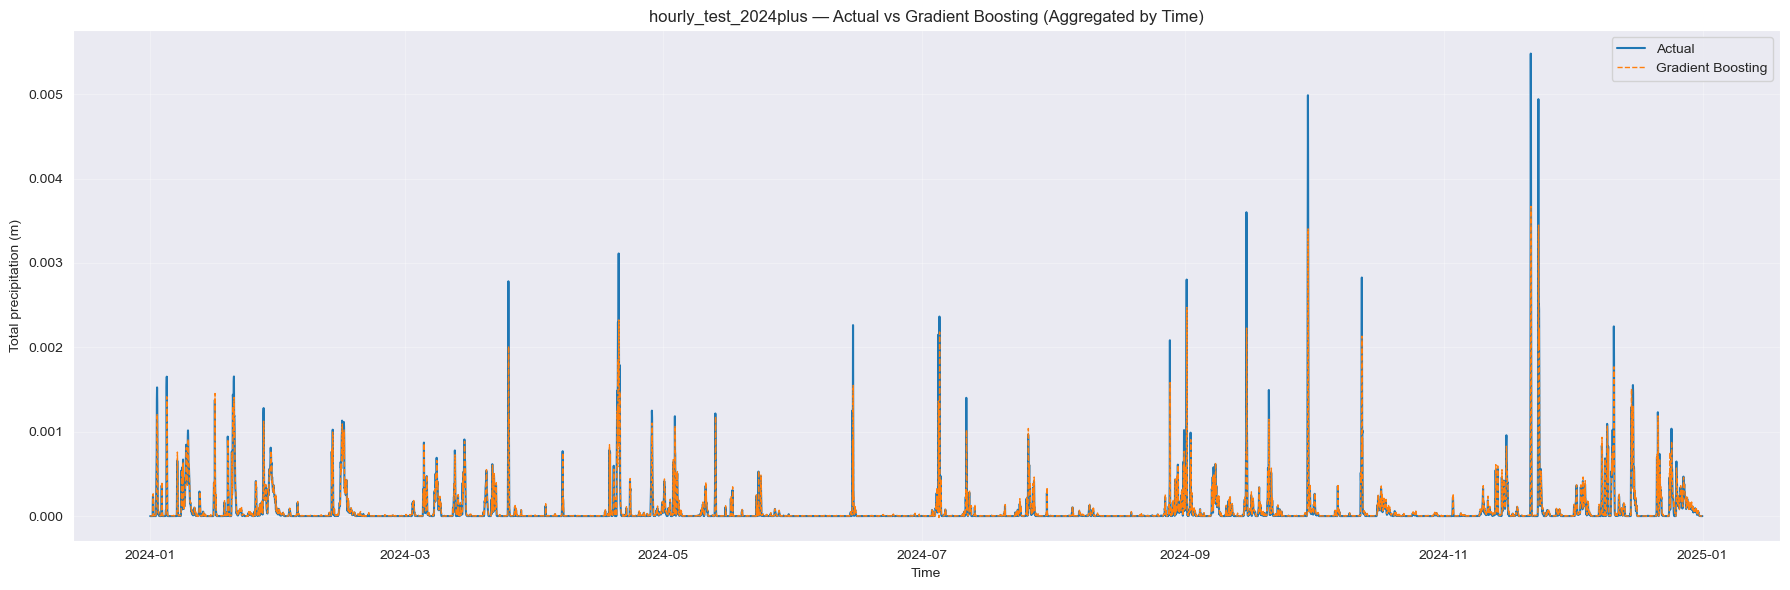

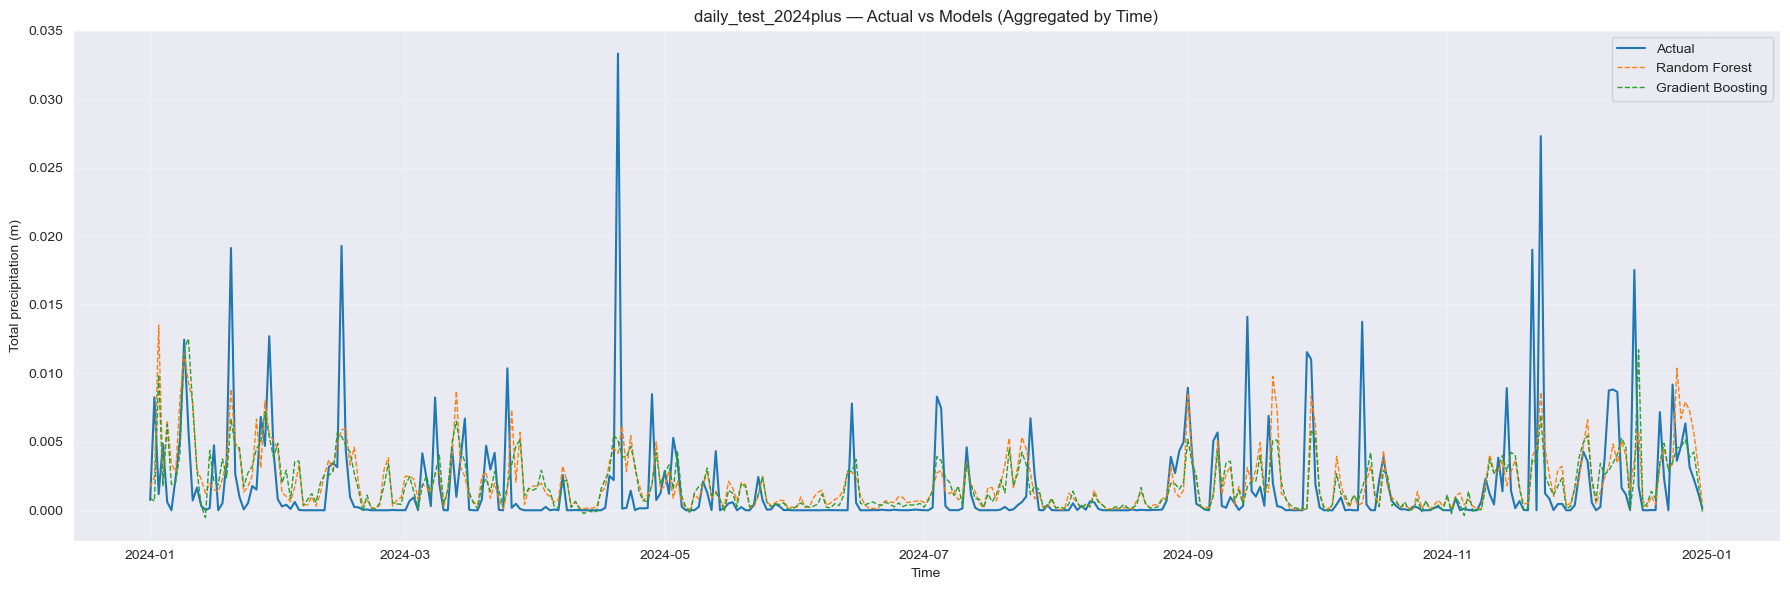

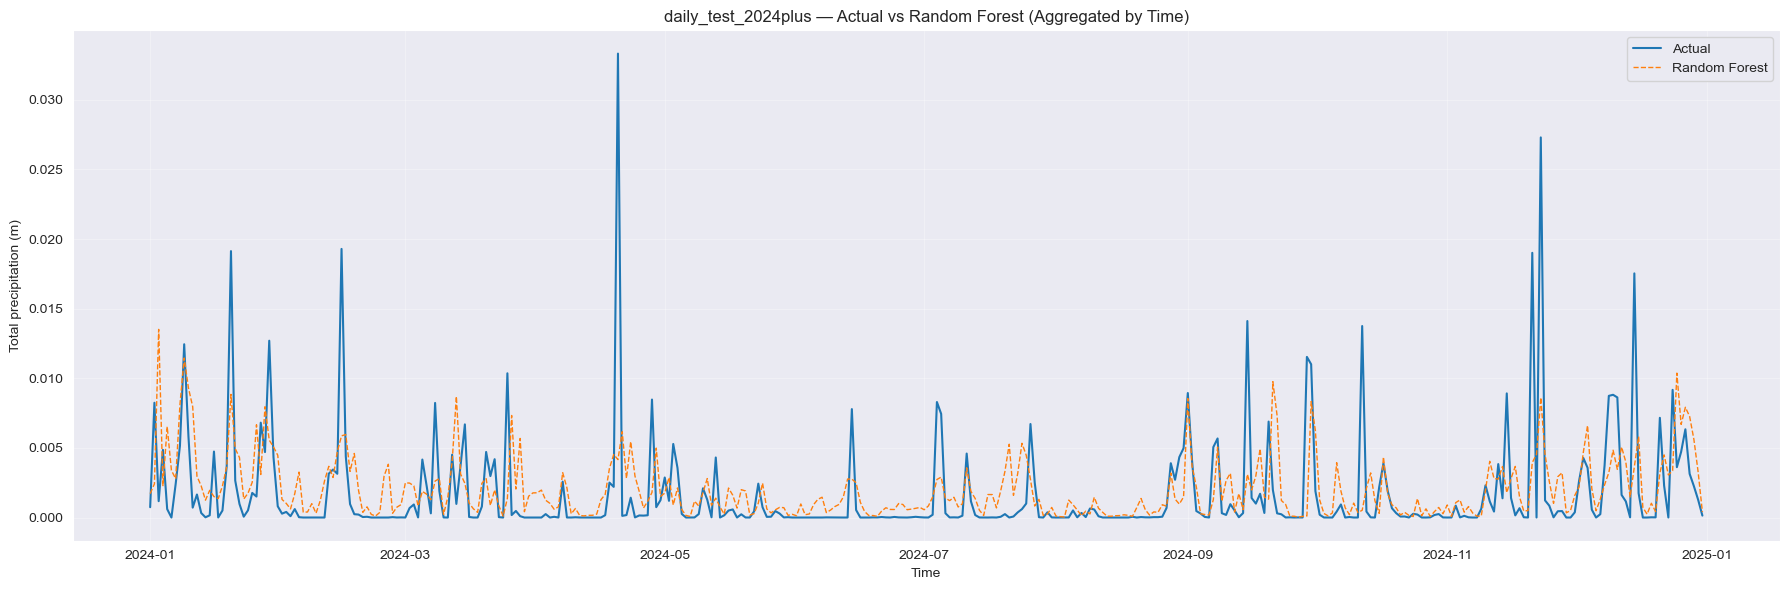

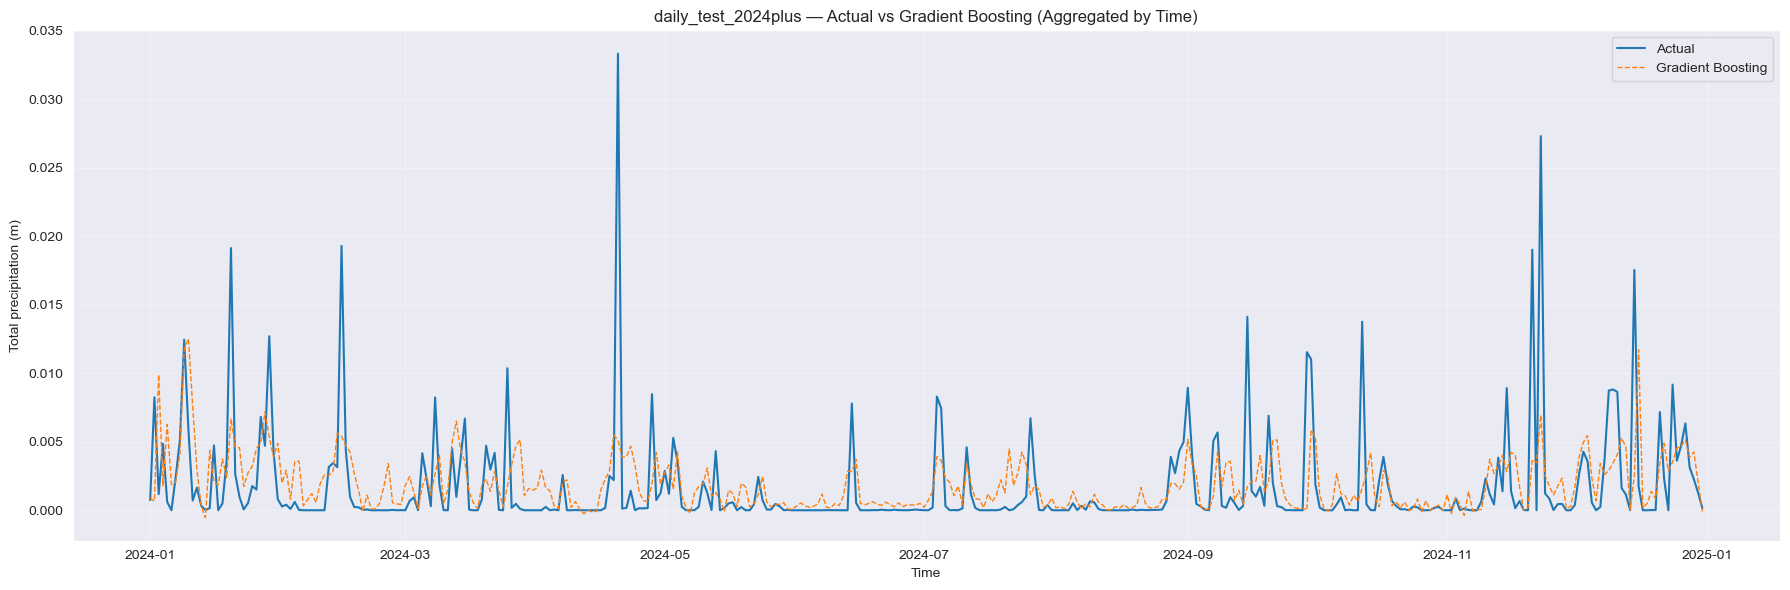

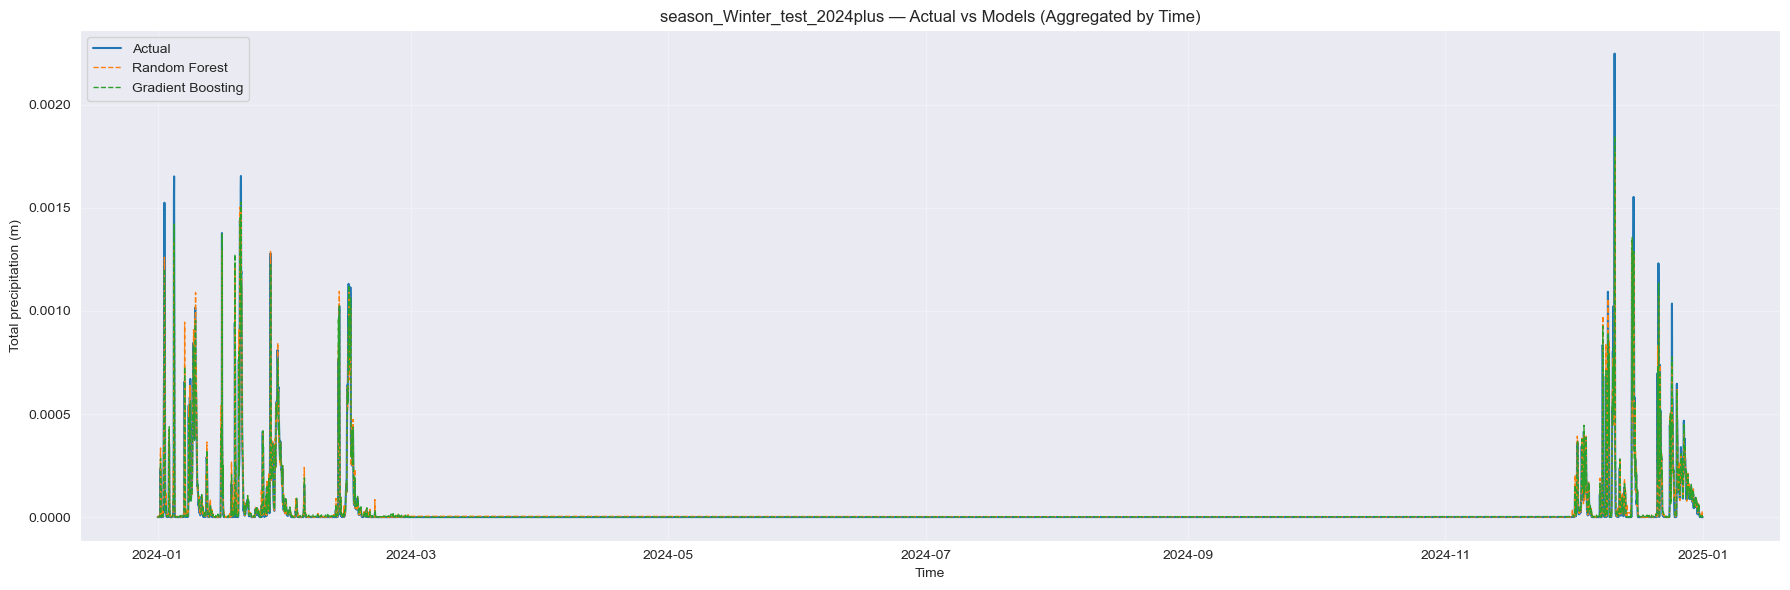

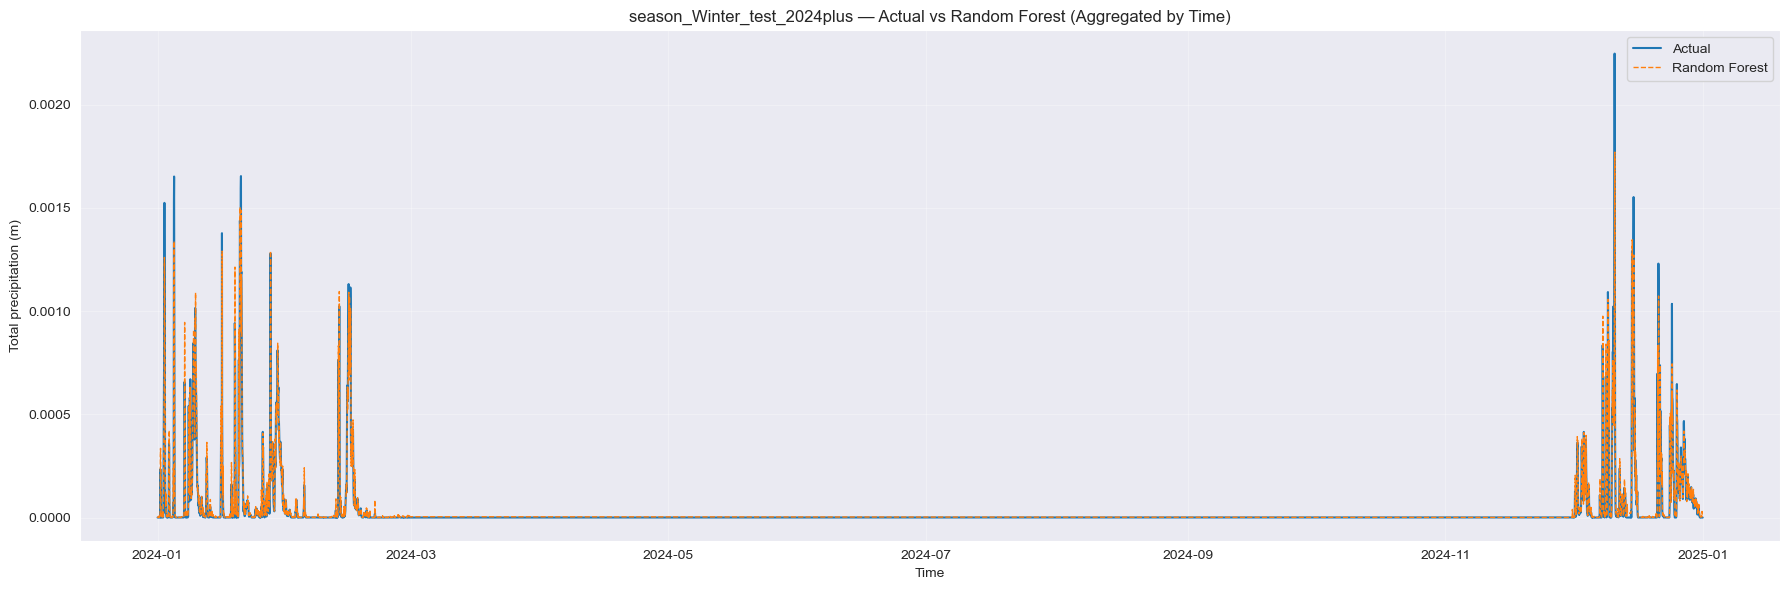

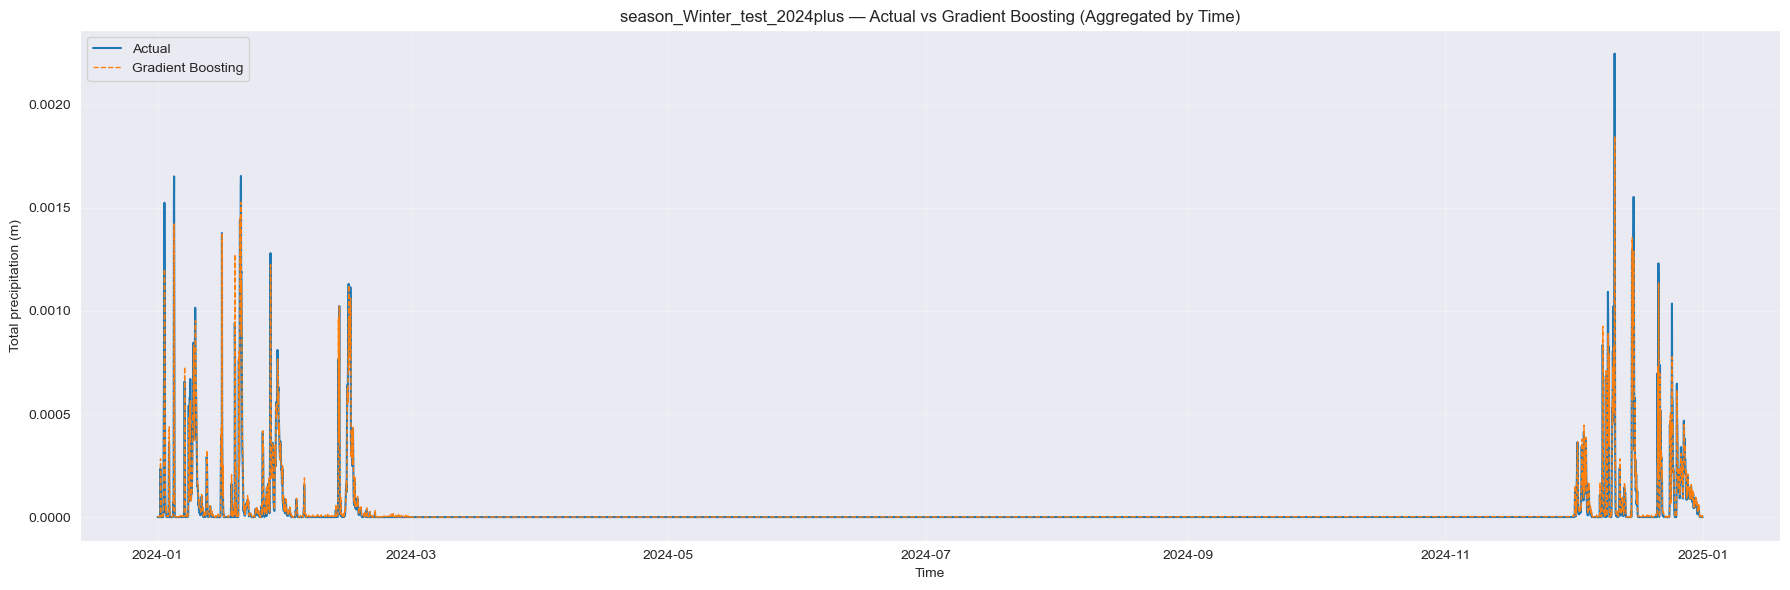

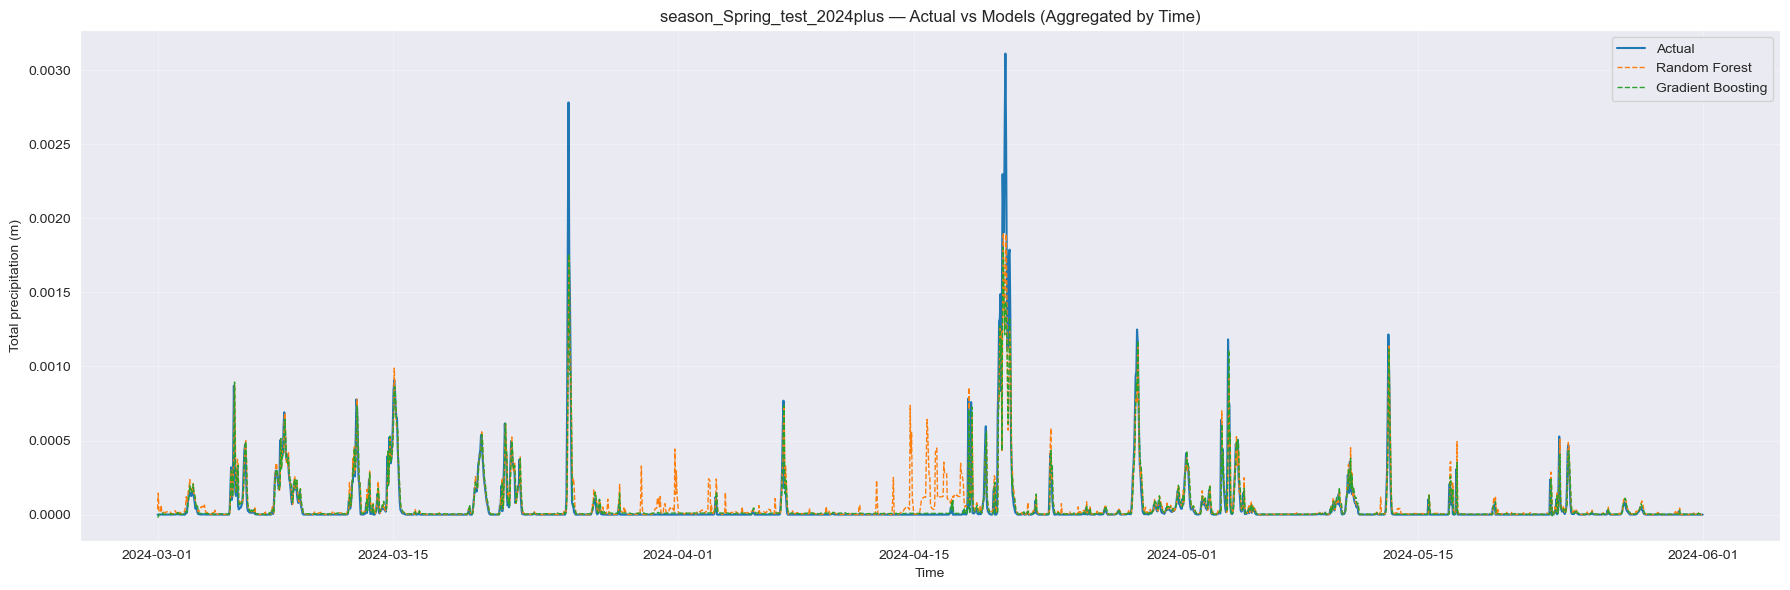

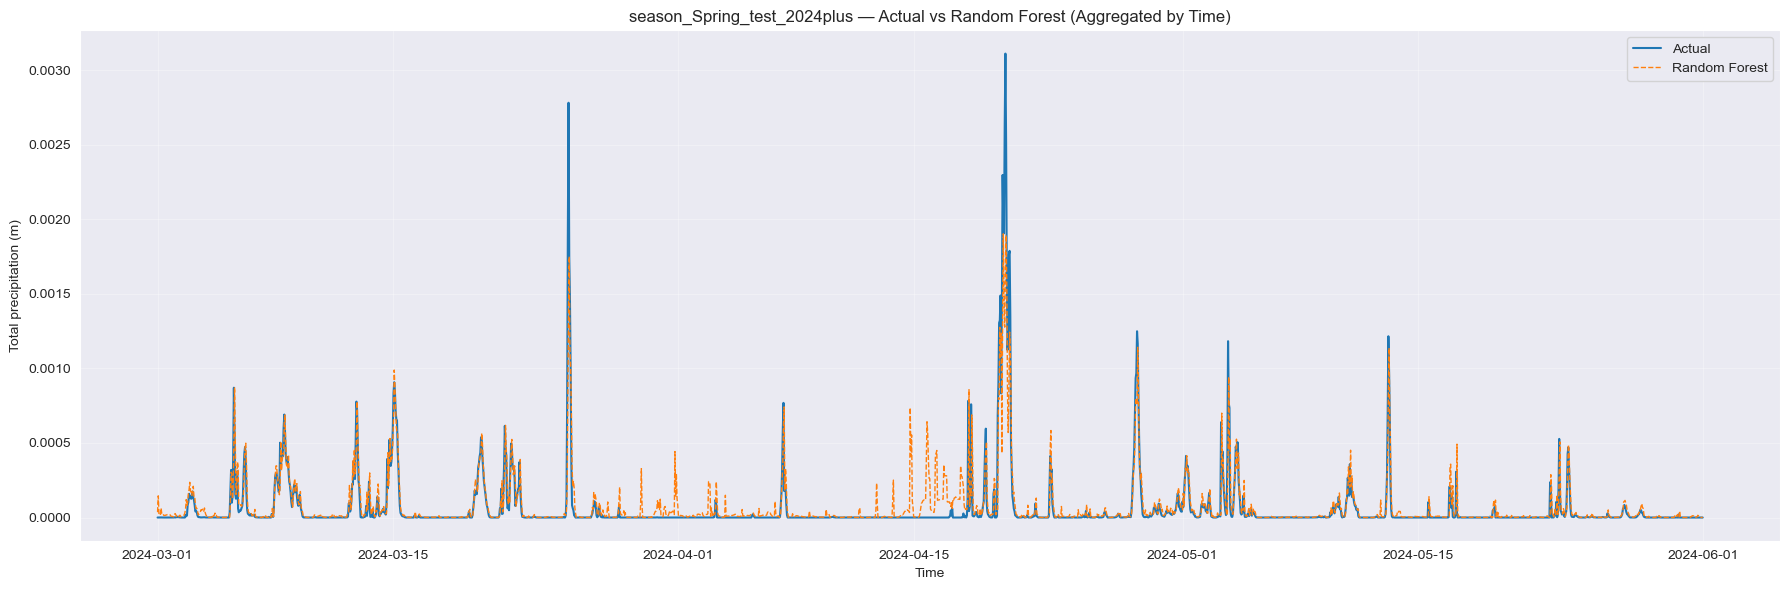

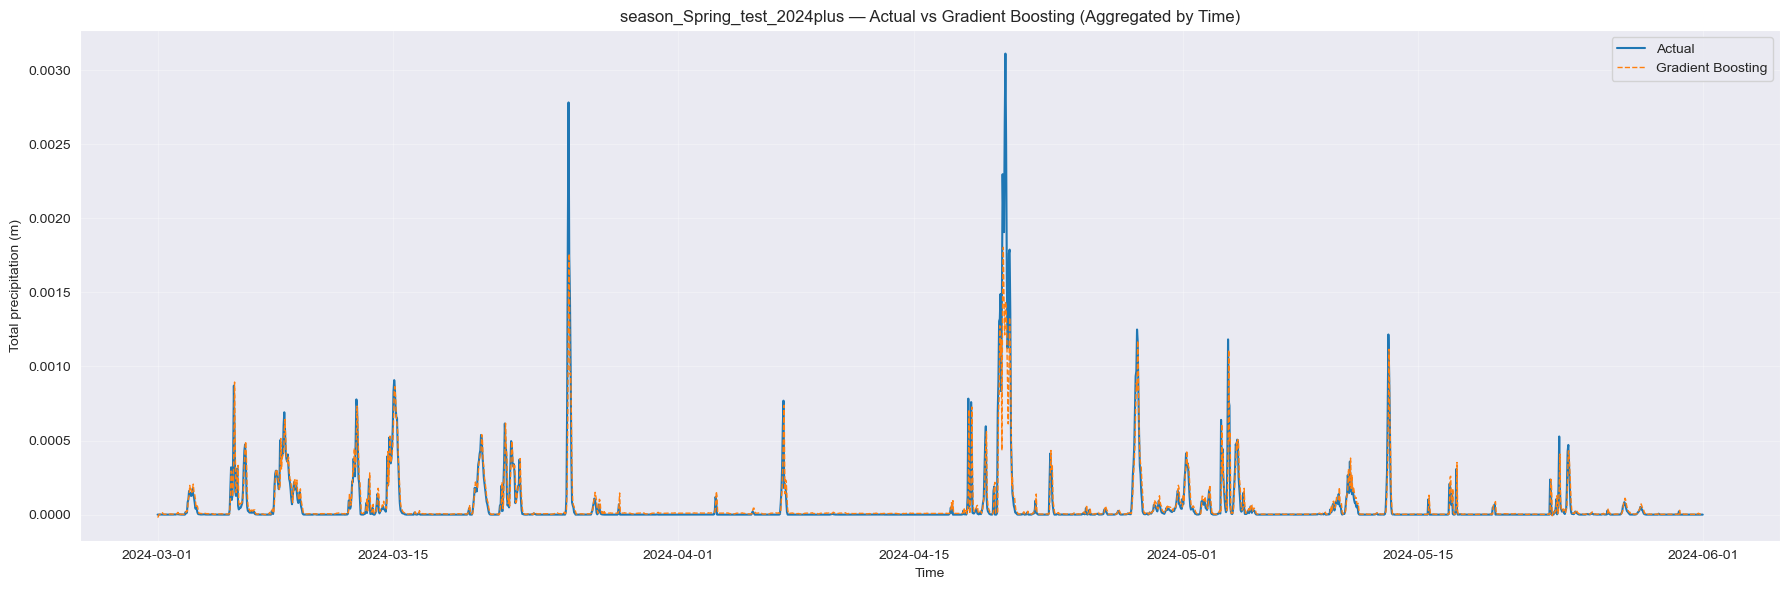

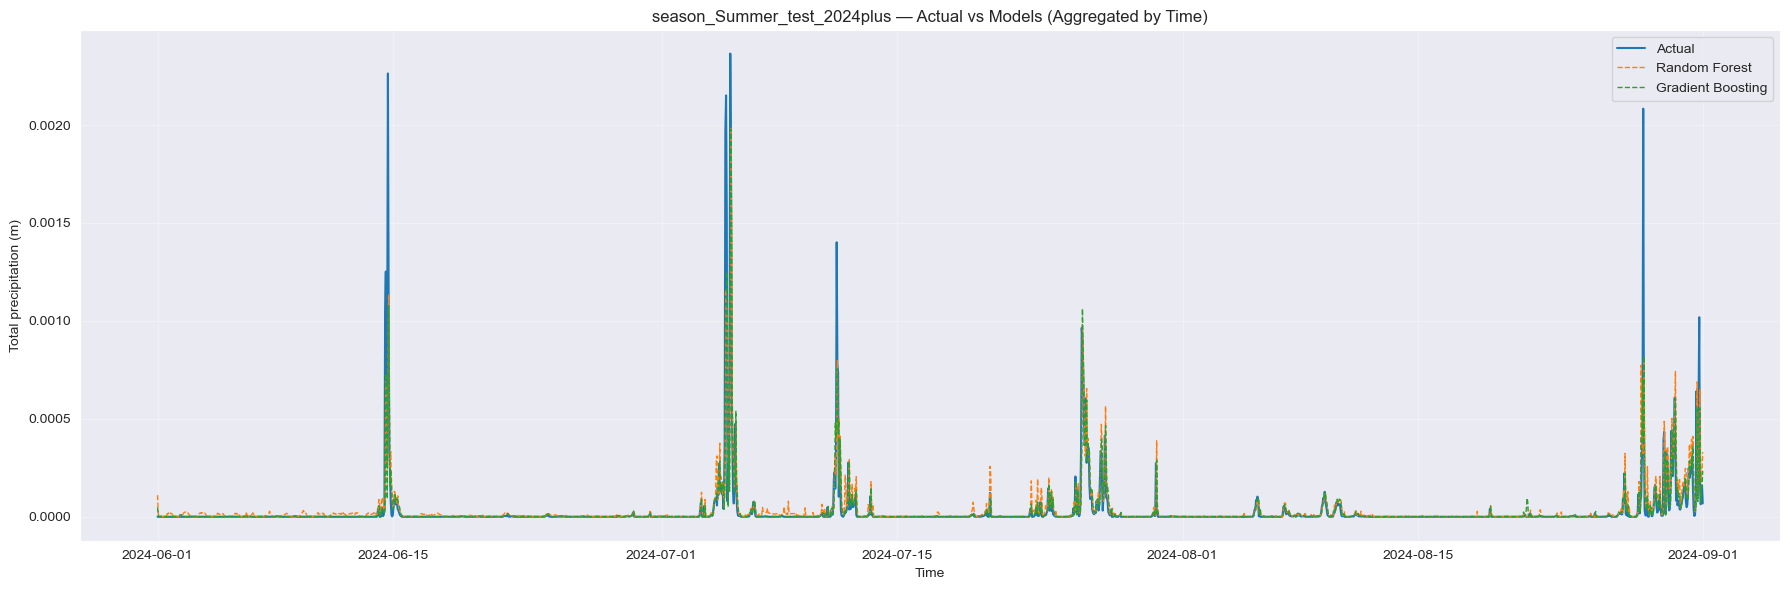

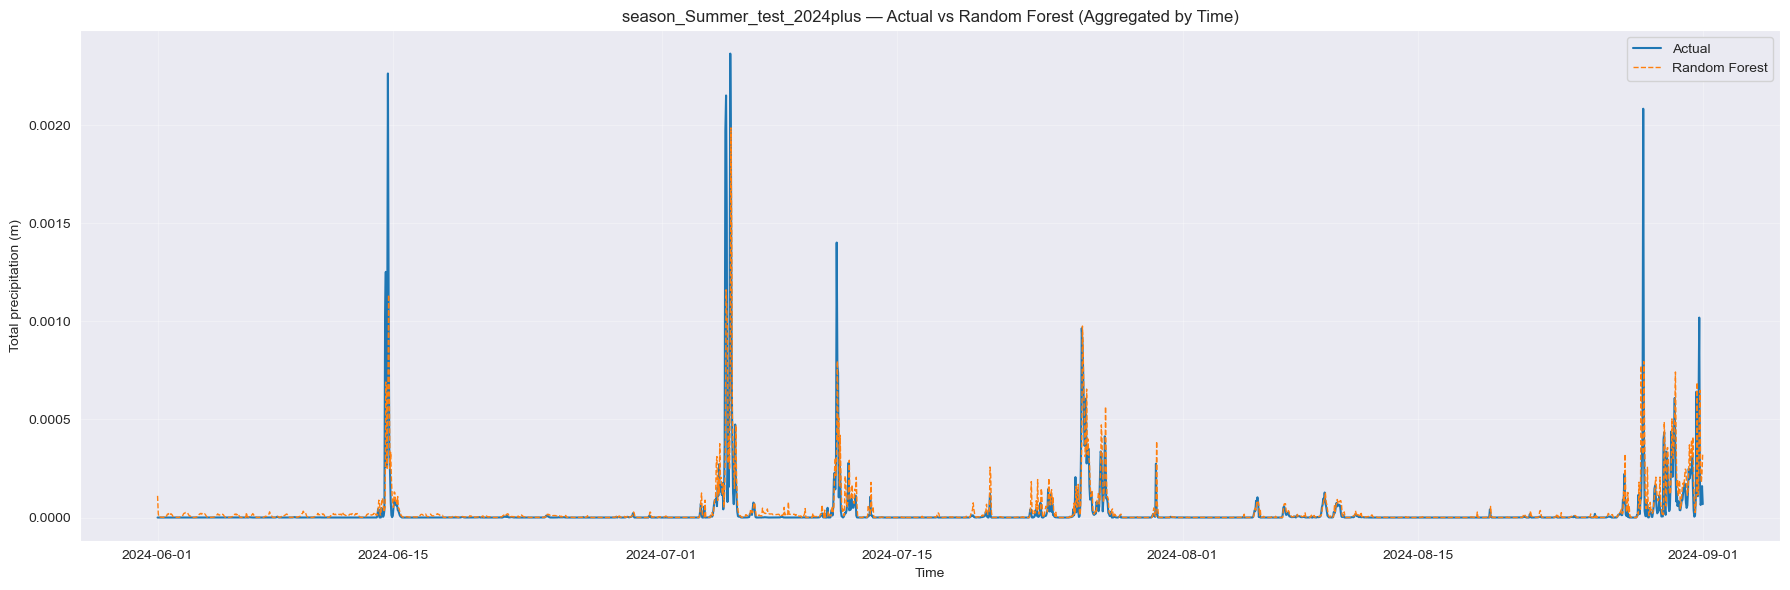

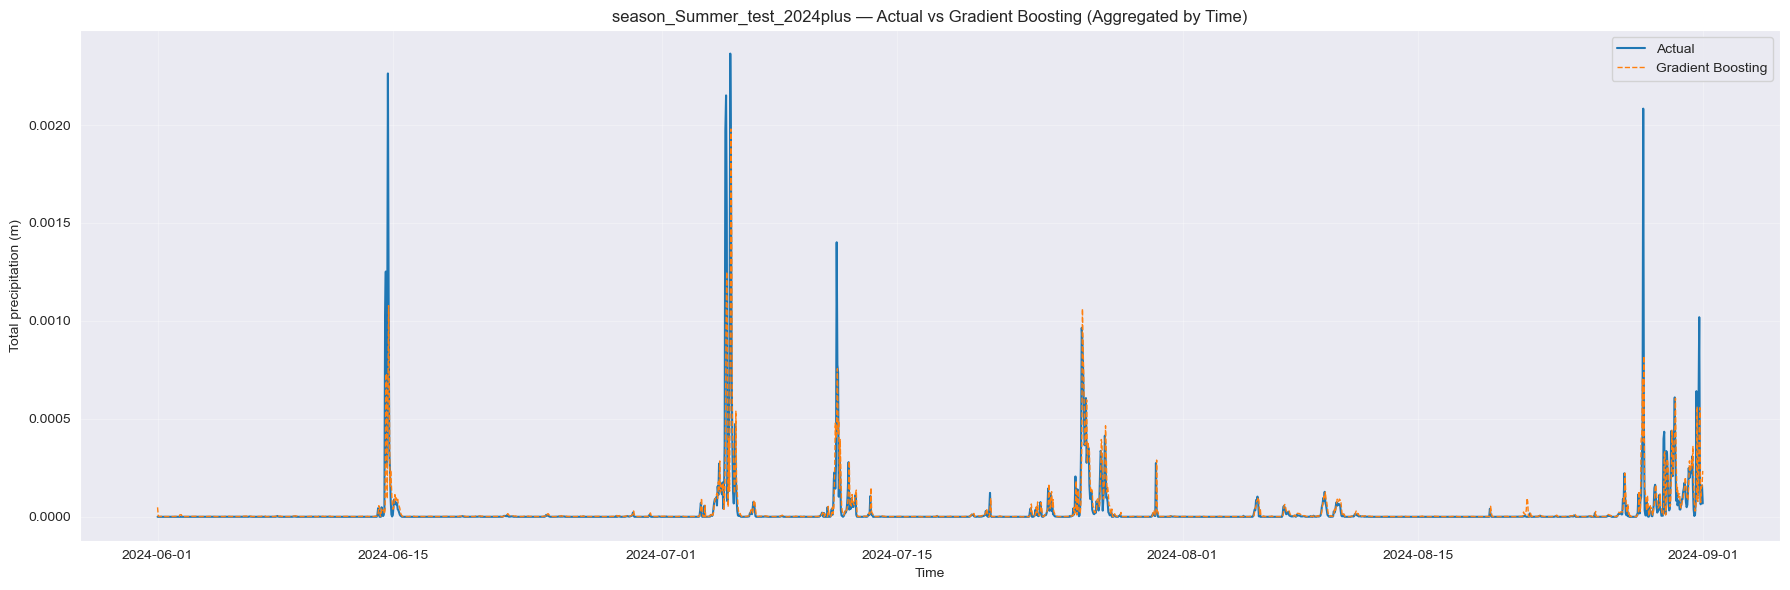

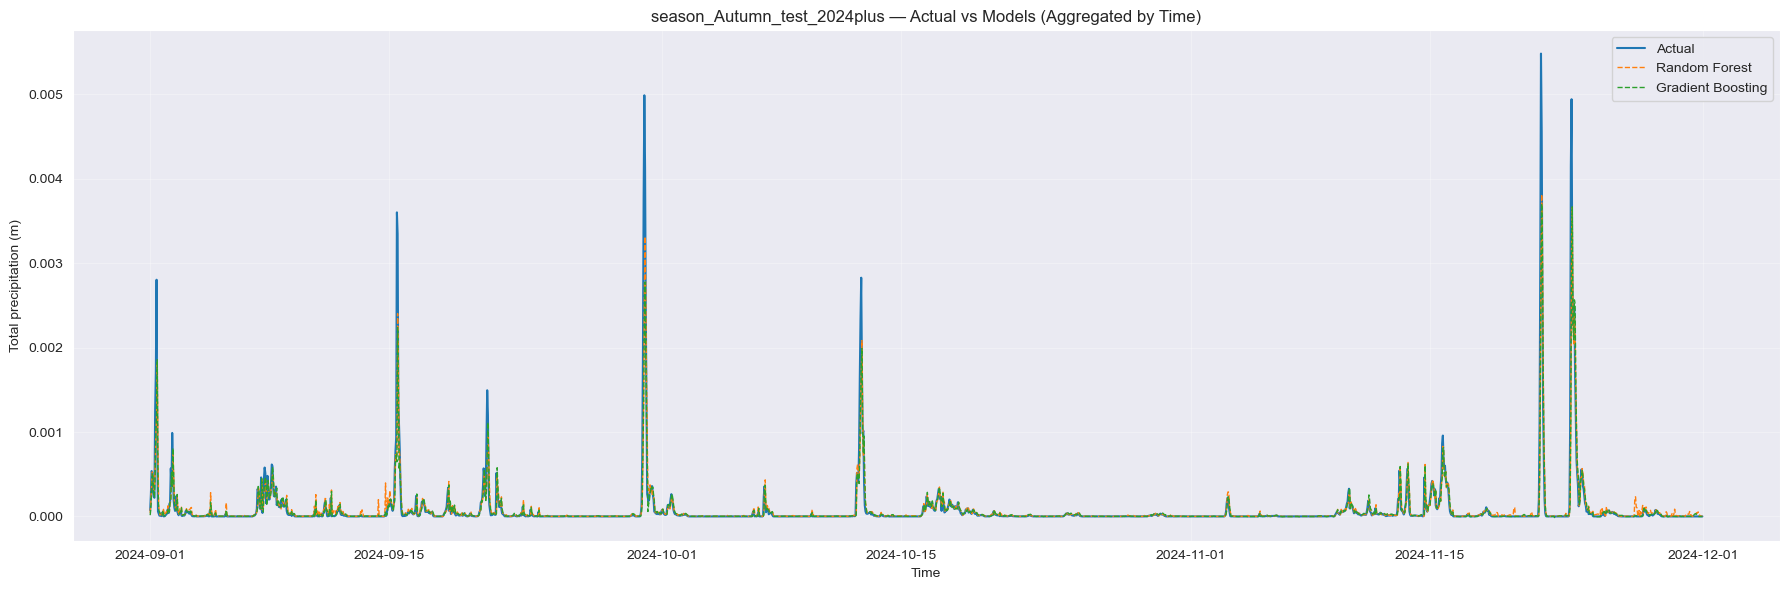

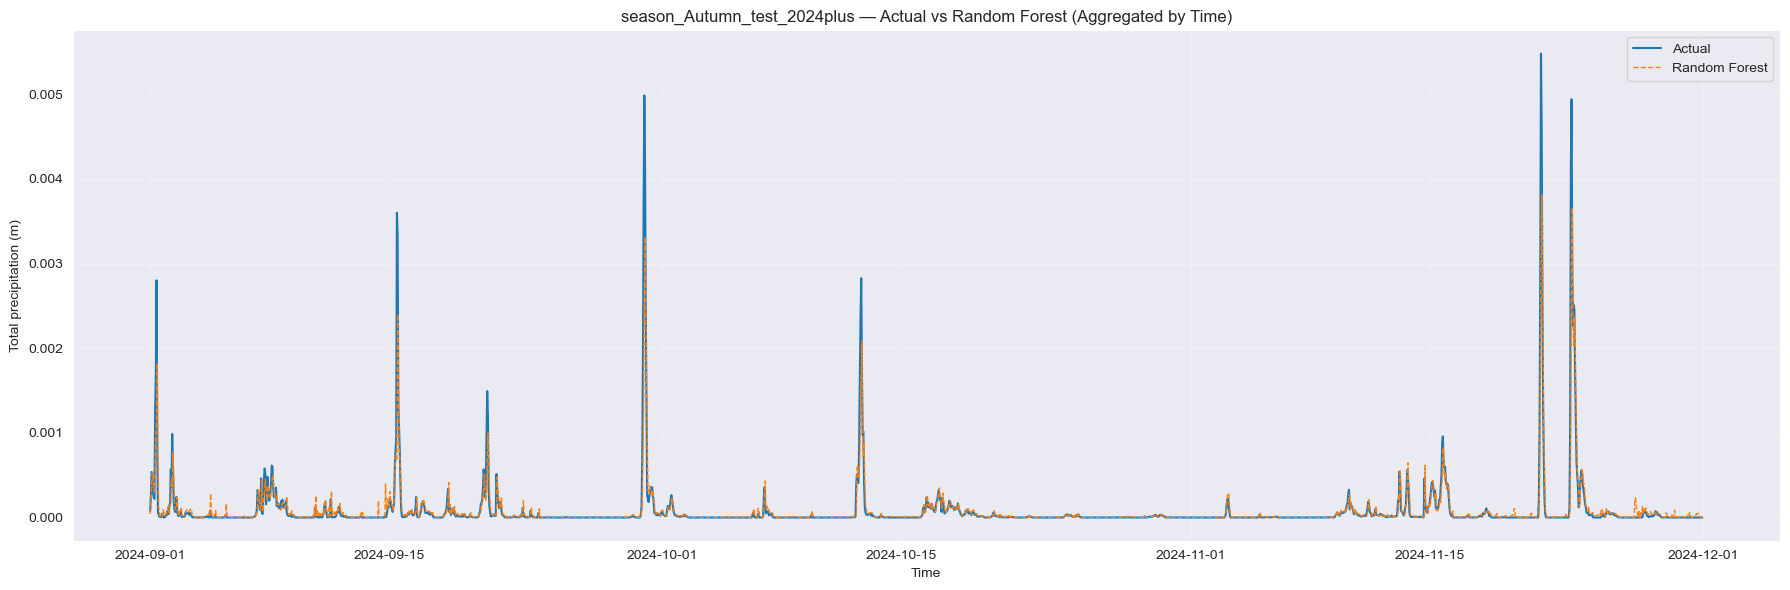

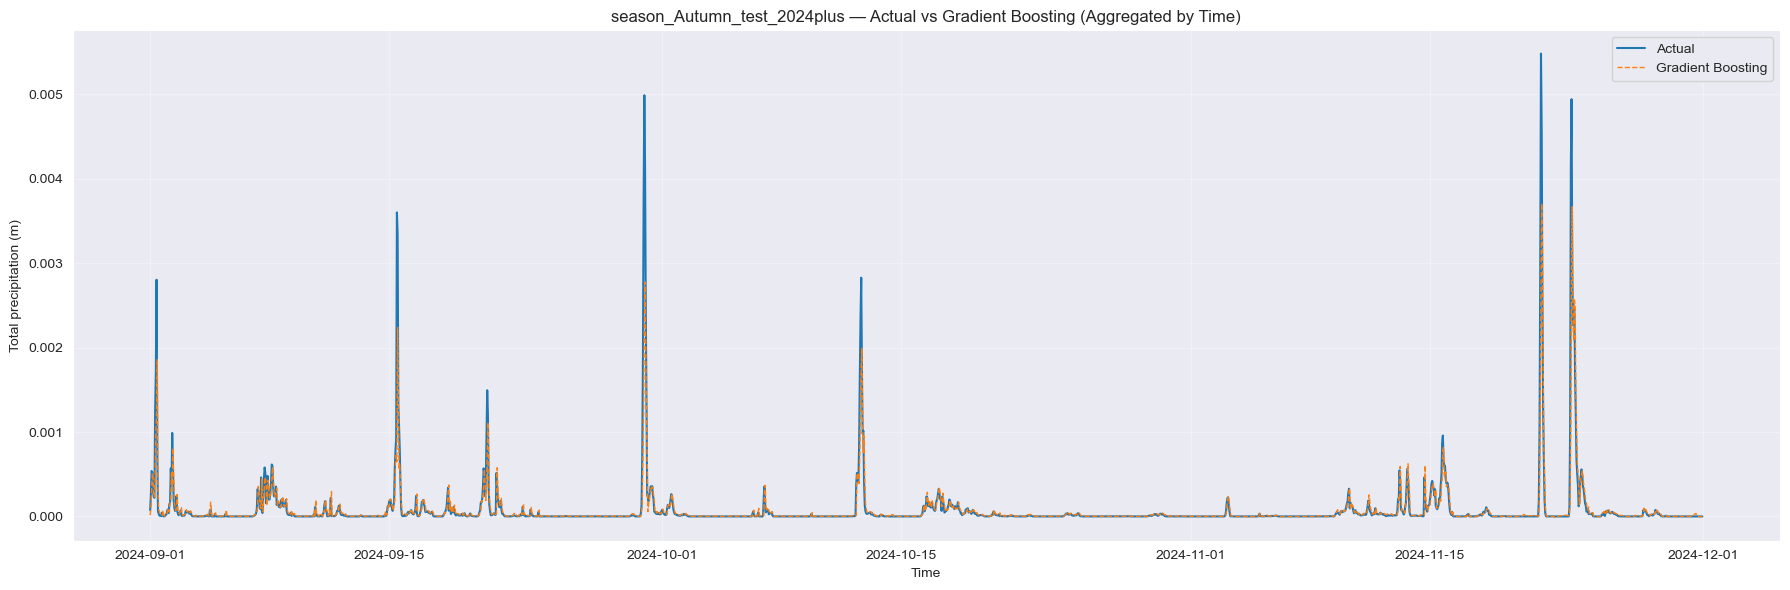


=== All Metrics (Hourly, Daily, Seasonal) ===
                                                                  MSE  \
Scenario         Subset               Model                             
Daily            Test_2024plus        Gradient Boosting  1.323683e-05   
                                      Random Forest      1.401446e-05   
Hourly           Test_2024plus        Gradient Boosting  2.325204e-08   
                                      Random Forest      2.414671e-08   
Seasonal(Hourly) Autumn_Test_2024plus Gradient Boosting  5.100233e-08   
                                      Random Forest      4.950001e-08   
                 Spring_Test_2024plus Gradient Boosting  1.532271e-08   
                                      Random Forest      1.877107e-08   
                 Summer_Test_2024plus Gradient Boosting  1.617121e-08   
                                      Random Forest      1.723151e-08   
                 Winter_Test_2024plus Gradient Boosting  1.361427e-08   
    

In [19]:
# -*- coding: utf-8 -*-
"""
Forecast 'tp' (total precipitation) with leakage-safe features and time-based split.

What this script does (no forecasts, plots not saved):
1) HOURLY (original):
   - Train on < 2024, test on 2024+
   - Show time-series plots (combined + per-model) without saving

2) DAILY-MAPPED:
   - Aggregate to daily per (lat, lon): tp = sum, continuous vars = mean
   - Rebuild leakage-safe lags/rolls on daily data
   - Train on < 2024, test on 2024+
   - Show time-series plots (combined + per-model) without saving

3) PER-SEASON (hourly data):
   - Seasons: Winter(DJF), Spring(MAM), Summer(JJA), Autumn(SON)
   - For each season: train < 2024 rows for that season; test >= 2024 rows for that season
   - Show time-series plots (combined + per-model) without saving

Outputs:
- CSVs with metrics and predictions to OUT_DIR (plots are NOT saved).
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# -----------------------------
# Config
# -----------------------------
CSV_PATH = "../data/combined_with_modisf_tpw.csv"  # change if needed
OUT_DIR  = os.path.dirname(CSV_PATH) if os.path.isdir(os.path.dirname(CSV_PATH)) else os.getcwd()

RANDOM_STATE = 42
MODELS = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE
    ),
}

CANDIDATE_FEATURES = [
    "latitude", "longitude",
    "ir_terra", "nir_terra", "modis_ir_cm", "modis_nir_cm",
    "hour", "dayofweek", "month", "dayofyear",
    "t2m_C_lag1", "t2m_C_lag2", "t2m_C_roll3", "t2m_C_roll7",
    "tp_lag1", "tp_lag2", "tp_roll3", "tp_roll7",
]
TARGET = "tp"

SEASON_MONTHS = {
    "Winter": [12, 1, 2],
    "Spring": [3, 4, 5],
    "Summer": [6, 7, 8],
    "Autumn": [9, 10, 11]
}

# -----------------------------
# Helpers
# -----------------------------
def add_calendar(df, time_col="valid_time"):
    df["hour"]      = df[time_col].dt.hour
    df["dayofweek"] = df[time_col].dt.dayofweek
    df["month"]     = df[time_col].dt.month
    df["dayofyear"] = df[time_col].dt.dayofyear
    return df

def add_lags_rolls(df, cols, group_keys=("latitude", "longitude"), lags=(1,2), rolls=(3,7)):
    df = df.copy()
    for col in cols:
        if col not in df.columns:
            continue
        for L in lags:
            df[f"{col}_lag{L}"] = df.groupby(list(group_keys))[col].shift(L)
        for W in rolls:
            df[f"{col}_roll{W}"] = (
                df.groupby(list(group_keys))[col]
                  .transform(lambda s: s.shift(1).rolling(W, min_periods=1).mean())
            )
    return df

def select_features(df, candidate):
    return [c for c in candidate if c in df.columns]

def fit_predict(models, X_train, y_train, X_test, y_test):
    imp = SimpleImputer(strategy="mean")
    Xtr = imp.fit_transform(X_train)
    Xte = imp.transform(X_test)

    preds = {}
    metrics = {}
    for name, model in models.items():
        model.fit(Xtr, y_train)
        y_hat = model.predict(Xte)
        preds[name] = y_hat
        metrics[name] = {
            "MSE": mean_squared_error(y_test, y_hat),
            "R2":  r2_score(y_test, y_hat)
        }
    return imp, preds, metrics

def agg_time_series(df_with_preds, time_col="valid_time", actual_col="actual", pred_cols=()):
    cols = [actual_col] + list(pred_cols)
    cols = [c for c in cols if c in df_with_preds.columns]
    return df_with_preds.groupby(time_col)[cols].mean(numeric_only=True)

def save_csv(df, path):
    df.to_csv(path, index=False)
    print(f"[Saved] {path}")

def season_filter(df, season_name):
    months = SEASON_MONTHS[season_name]
    return df[df["month"].isin(months)].copy()

def print_metrics_table(metrics_rows, title):
    df = pd.DataFrame(metrics_rows)
    if not df.empty:
        pivot = df.pivot_table(index=["Scenario","Subset","Model"], values=["MSE","R2"], aggfunc="first")
        print(f"\n=== {title} ===")
        print(pivot.sort_index())
    return df

# --- NEW: helper to show time-series plots for all models (no saving) ---
def plot_timeseries_bundle(agg_df, scenario_tag):
    """
    agg_df: index=time; columns: 'actual' + model names
    scenario_tag: short name for figure titles, e.g. 'hourly_test_2024plus', 'daily_test_2024plus',
                  'season_Winter_test_2024plus'
    """
    # 1) Combined plot (Actual + all models)
    plt.figure(figsize=(18, 6))
    if "actual" in agg_df.columns:
        plt.plot(agg_df.index, agg_df["actual"], label="Actual", linewidth=1.5)
    for col in agg_df.columns:
        if col == "actual":
            continue
        plt.plot(agg_df.index, agg_df[col], label=col, linestyle="--", linewidth=1.0)
    plt.title(f"{scenario_tag} — Actual vs Models (Aggregated by Time)")
    plt.xlabel("Time")
    plt.ylabel("Total precipitation (m)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 2) Per-model plots (Actual vs one model)
    model_cols = [c for c in agg_df.columns if c != "actual"]
    for mcol in model_cols:
        plt.figure(figsize=(18, 6))
        if "actual" in agg_df.columns:
            plt.plot(agg_df.index, agg_df["actual"], label="Actual", linewidth=1.5)
        plt.plot(agg_df.index, agg_df[mcol], label=mcol, linestyle="--", linewidth=1.0)
        plt.title(f"{scenario_tag} — Actual vs {mcol} (Aggregated by Time)")
        plt.xlabel("Time")
        plt.ylabel("Total precipitation (m)")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# -----------------------------
# Load & prepare base (hourly)
# -----------------------------
data = pd.read_csv(CSV_PATH)
data["valid_time"] = pd.to_datetime(data["valid_time"], errors="coerce")
data = data.dropna(subset=["valid_time"]).copy()
data.sort_values(by=["valid_time", "latitude", "longitude"], inplace=True)

# Calendar & leakage-safe lags/rolls on HOURLY
data = add_calendar(data, "valid_time")
data = add_lags_rolls(data, cols=["tp", "t2m_C"], group_keys=("latitude","longitude"))

# Keep rows with valid target
data = data.dropna(subset=["tp"]).copy()

# Feature list (hourly)
features_hr = select_features(data, CANDIDATE_FEATURES)

# Split (hourly)
train_mask_hr = data["valid_time"] < pd.Timestamp("2024-01-01")
train_hr = data.loc[train_mask_hr].copy()
test_hr  = data.loc[~train_mask_hr].copy()

Xtr_hr, ytr_hr = train_hr[features_hr], train_hr["tp"]
Xte_hr, yte_hr = test_hr[features_hr],  test_hr["tp"]

# Train & evaluate (hourly)
imp_hr, preds_hr, metrics_hr = fit_predict(MODELS, Xtr_hr, ytr_hr, Xte_hr, yte_hr)

# Collect metrics rows
metrics_rows = []
for mname, m in metrics_hr.items():
    metrics_rows.append({
        "Scenario":"Hourly", "Subset":"Test_2024plus", "Model":mname,
        "MSE":m["MSE"], "R2":m["R2"]
    })

# Predictions DataFrame (hourly test)
test_pred_hr = test_hr[["valid_time","latitude","longitude","tp"]].rename(columns={"tp":"actual"}).copy()
for mname, yhat in preds_hr.items():
    test_pred_hr[mname] = yhat

# Plot hourly aggregated series (combined + per-model) — shown only
agg_hr = agg_time_series(test_pred_hr, "valid_time", "actual", pred_cols=list(MODELS.keys()))
plot_timeseries_bundle(agg_hr, "hourly_test_2024plus")

# -----------------------------
# DAILY-MAPPED VERSION
# -----------------------------
# 1) Aggregate to daily per (date, lat, lon)
df_daily = data.copy()
df_daily["date"] = df_daily["valid_time"].dt.floor("D")

# Define how to aggregate:
#  - tp: sum over day
#  - continuous features (t2m_C, ir/nir/modis): mean over day
agg_map = {}
if "tp" in df_daily.columns:
    agg_map["tp"] = "sum"
for col in ["t2m_C","ir_terra","nir_terra","modis_ir_cm","modis_nir_cm"]:
    if col in df_daily.columns:
        agg_map[col] = "mean"

group_cols = ["date","latitude","longitude"]
df_daily = df_daily.groupby(group_cols, as_index=False).agg(agg_map)

# Rebuild calendar on daily
df_daily = df_daily.rename(columns={"date":"valid_time"})
df_daily = add_calendar(df_daily, "valid_time")

# Rebuild leakage-safe lags/rolls on DAILY data
df_daily = df_daily.sort_values(by=["valid_time","latitude","longitude"]).copy()
df_daily = add_lags_rolls(df_daily, cols=["tp","t2m_C"], group_keys=("latitude","longitude"))

# Drop rows without target
df_daily = df_daily.dropna(subset=["tp"]).copy()

# Features (daily)
features_d = select_features(df_daily, CANDIDATE_FEATURES)

# Split (daily)
train_mask_d = df_daily["valid_time"] < pd.Timestamp("2024-01-01")
train_d = df_daily.loc[train_mask_d].copy()
test_d  = df_daily.loc[~train_mask_d].copy()

Xtr_d, ytr_d = train_d[features_d], train_d["tp"]
Xte_d, yte_d = test_d[features_d],  test_d["tp"]

# Train & evaluate (daily)
imp_d, preds_d, metrics_d = fit_predict(MODELS, Xtr_d, ytr_d, Xte_d, yte_d)

for mname, m in metrics_d.items():
    metrics_rows.append({
        "Scenario":"Daily", "Subset":"Test_2024plus", "Model":mname,
        "MSE":m["MSE"], "R2":m["R2"]
    })

# Predictions DataFrame (daily test)
test_pred_d = test_d[["valid_time","latitude","longitude","tp"]].rename(columns={"tp":"actual"}).copy()
for mname, yhat in preds_d.items():
    test_pred_d[mname] = yhat

# Plot daily aggregated series (combined + per-model) — shown only
agg_d = agg_time_series(test_pred_d, "valid_time", "actual", pred_cols=list(MODELS.keys()))
plot_timeseries_bundle(agg_d, "daily_test_2024plus")

# -----------------------------
# PER-SEASON (HOURLY DATA)
# -----------------------------
season_predictions = []  # to save concatenated seasonal predictions
for season in ["Winter","Spring","Summer","Autumn"]:
    # subset hourly data by season months
    df_s = add_calendar(data.copy(), "valid_time")
    df_s = df_s[df_s["month"].isin(SEASON_MONTHS[season])].copy()

    # lags/rolls on this seasonal subset
    df_s = df_s.sort_values(by=["valid_time","latitude","longitude"]).copy()
    df_s = add_lags_rolls(df_s, cols=["tp","t2m_C"], group_keys=("latitude","longitude"))

    df_s = df_s.dropna(subset=["tp"]).copy()
    if df_s.empty:
        print(f"[Season {season}] No rows after filtering; skipping.")
        continue

    feat_s = select_features(df_s, CANDIDATE_FEATURES)
    tr_mask = df_s["valid_time"] < pd.Timestamp("2024-01-01")
    tr_s = df_s.loc[tr_mask].copy()
    te_s = df_s.loc[~tr_mask].copy()

    if te_s.empty or tr_s.empty:
        print(f"[Season {season}] Not enough rows for split; skipping.")
        continue

    imp_s, preds_s, metrics_s = fit_predict(MODELS, tr_s[feat_s], tr_s["tp"], te_s[feat_s], te_s["tp"])

    for mname, m in metrics_s.items():
        metrics_rows.append({
            "Scenario":"Seasonal(Hourly)", "Subset":f"{season}_Test_2024plus", "Model":mname,
            "MSE":m["MSE"], "R2":m["R2"]
        })

    te_pred = te_s[["valid_time","latitude","longitude","tp"]].rename(columns={"tp":"actual"}).copy()
    for mname, yhat in preds_s.items():
        te_pred[mname] = yhat
    te_pred["Season"] = season
    season_predictions.append(te_pred)

    # plot per-season aggregated series (combined + per-model) — shown only
    agg_s = agg_time_series(te_pred, "valid_time", "actual", pred_cols=list(MODELS.keys()))
    plot_timeseries_bundle(agg_s, f"season_{season}_test_2024plus")

# -----------------------------
# SAVE: metrics & predictions (plots are not saved)
# -----------------------------
# 1) Metrics
metrics_df = print_metrics_table(metrics_rows, "All Metrics (Hourly, Daily, Seasonal)")
metrics_path = os.path.join(OUT_DIR, "metrics_overview.csv")
if not metrics_df.empty:
    save_csv(metrics_df, metrics_path)

# 2) Predictions
# Hourly test predictions
pred_hourly_path = os.path.join(OUT_DIR, "predictions_hourly_test_2024plus.csv")
save_csv(test_pred_hr, pred_hourly_path)

# Daily test predictions
pred_daily_path = os.path.join(OUT_DIR, "predictions_daily_test_2024plus.csv")
save_csv(test_pred_d, pred_daily_path)

# Seasonal predictions (concat)
if season_predictions:
    season_pred_all = pd.concat(season_predictions, axis=0, ignore_index=True)
    pred_seasonal_path = os.path.join(OUT_DIR, "predictions_seasonal_hourly_test_2024plus.csv")
    save_csv(season_pred_all, pred_seasonal_path)

print("\nDone. (No forecasts; plots were shown but not saved.)")


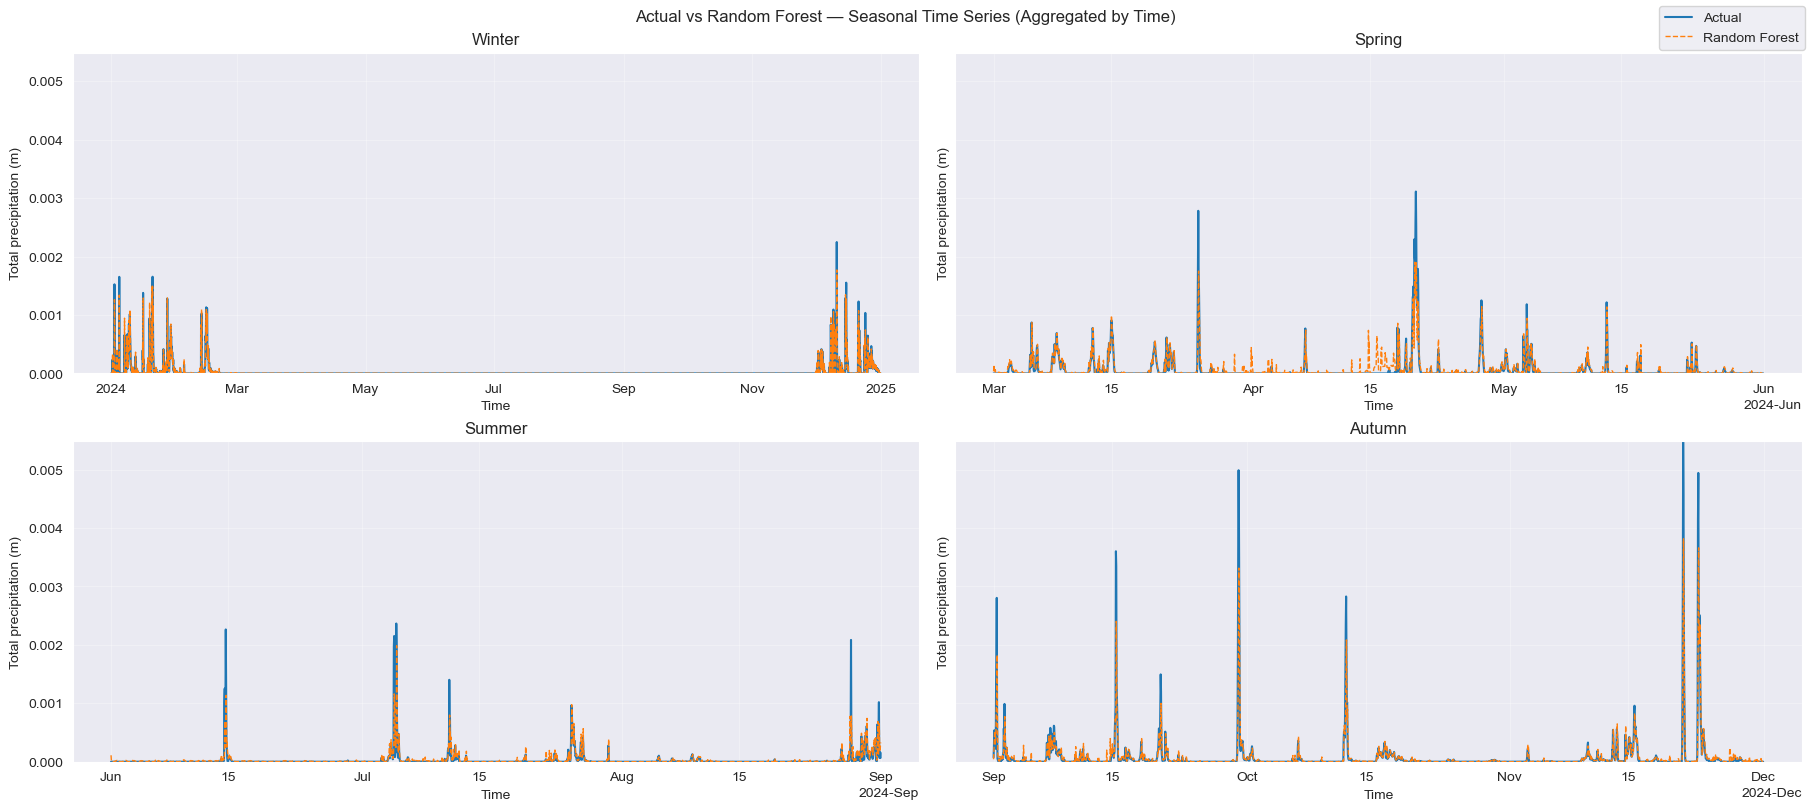

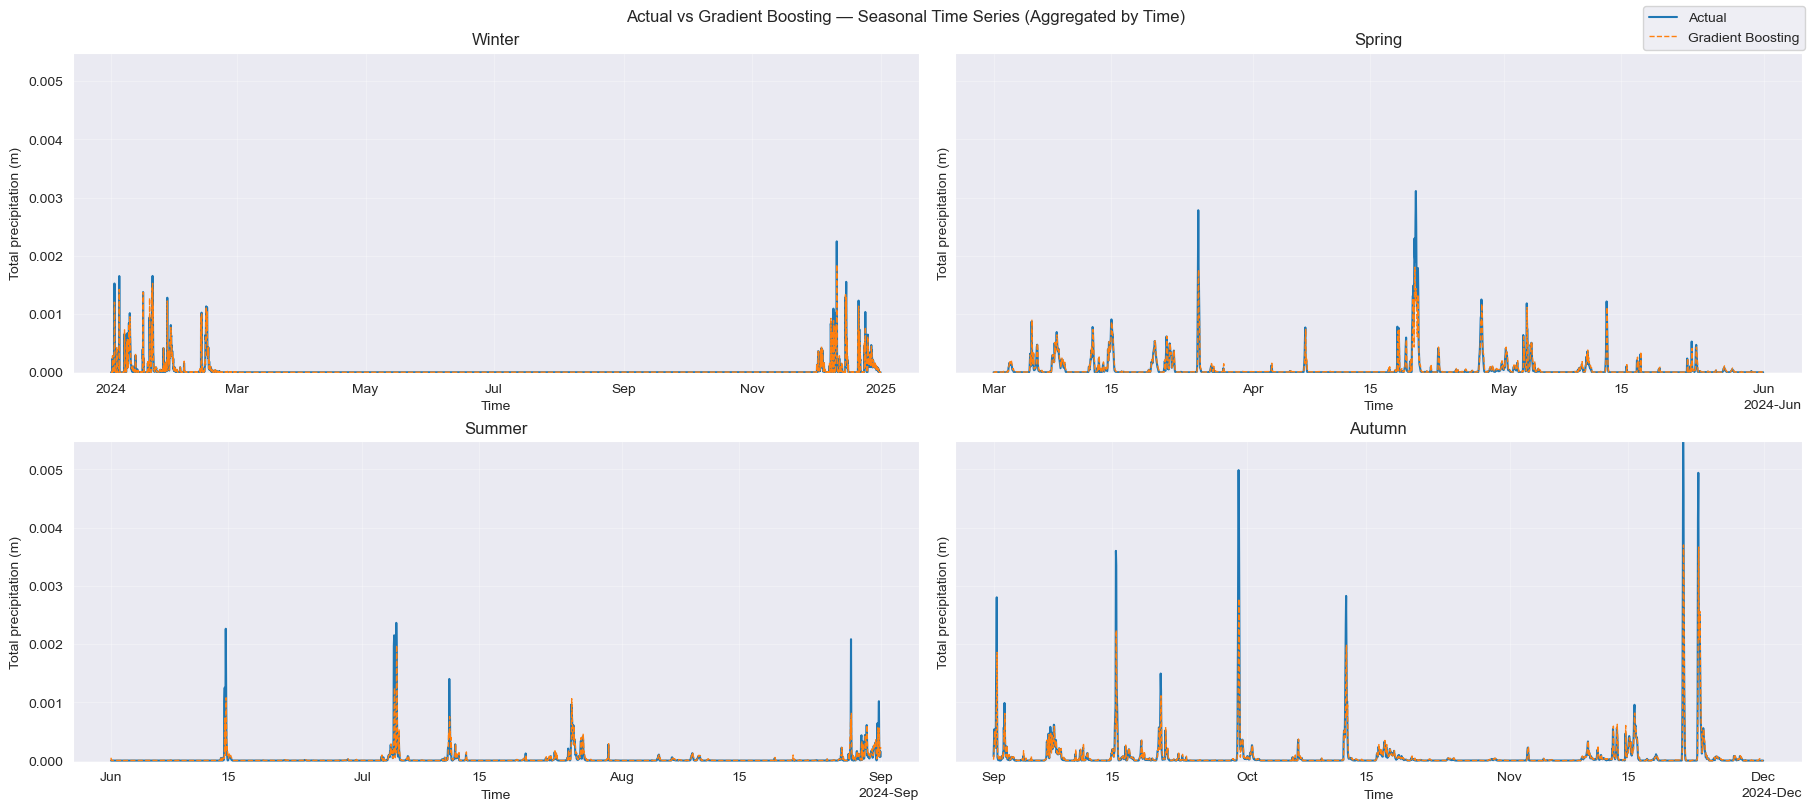

In [20]:
# === Next Cell: Time-series grids per model (2×2 seasons) — no retrain, nothing saved ===
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ------------- options you can tweak -------------
SEASON_ORDER = ["Winter","Spring","Summer","Autumn"]
MODEL_LIST   = None   # None for all models, or e.g. ["Random Forest","Gradient Boosting"]
CONVERT_TO_KG_M2 = False  # True → y-axis in kg/m² (≈ mm); assumes 'tp' in meters
# -------------------------------------------------

def _get_seasonal_df():
    # Prefer in-memory from previous cell
    if "season_pred_all" in globals():
        return season_pred_all.copy()
    if "season_predictions" in globals() and season_predictions:
        return pd.concat(season_predictions, axis=0, ignore_index=True)
    # Fallback to CSV saved previously
    try:
        path_ = pred_seasonal_path
    except NameError:
        path_ = os.path.join(OUT_DIR, "predictions_seasonal_hourly_test_2024plus.csv")
    if not os.path.exists(path_):
        raise FileNotFoundError(
            f"Could not find seasonal predictions at:\n{path_}\n"
            "Run the training cell once to produce them."
        )
    return pd.read_csv(path_, parse_dates=["valid_time"])

df = _get_seasonal_df()

# Sanity checks
needed = {"valid_time","latitude","longitude","actual","Season"}
missing = needed - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Decide which model columns to plot
base_cols = {"valid_time","latitude","longitude","actual","Season"}
model_cols = [c for c in df.columns if c not in base_cols]
if MODEL_LIST:
    model_cols = [m for m in model_cols if m in MODEL_LIST]
if not model_cols:
    raise ValueError("No model prediction columns found to plot.")

# Optional unit conversion
unit_label = "Total precipitation (m)"
if CONVERT_TO_KG_M2:
    df["actual"] = df["actual"] * 1000.0
    for m in model_cols:
        df[m] = df[m] * 1000.0
    unit_label = "Total precipitation (kg/m²)"

# Helper: aggregate to time series (mean across lat/lon at each timestamp)
def agg_time_series(sub):
    cols = ["actual"] + model_cols
    # average over the grid per timestamp
    out = sub.groupby("valid_time")[cols].mean(numeric_only=True).sort_index()
    return out

# Precompute aggregated time series per season
agg_by_season = {}
for season in SEASON_ORDER:
    s = df[df["Season"] == season]
    if s.empty:
        agg_by_season[season] = None
    else:
        agg_by_season[season] = agg_time_series(s)

# Plot a 2×2 grid per model
for m in model_cols:
    fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharex=False, sharey=True, constrained_layout=True)
    axes = axes.ravel()

    # Determine a consistent y-limit across seasons for this model
    ymins, ymaxs = [], []
    for season in SEASON_ORDER:
        ts = agg_by_season.get(season)
        if ts is None or ts.empty:
            continue
        ymins.append(np.nanmin([ts["actual"].min(), ts[m].min()]))
        ymaxs.append(np.nanmax([ts["actual"].max(), ts[m].max()]))
    if ymins and ymaxs:
        ymin, ymax = np.nanmin(ymins), np.nanmax(ymaxs)
    else:
        ymin, ymax = None, None

    for ax, season in zip(axes, SEASON_ORDER):
        ts = agg_by_season.get(season)
        ax.set_title(season)
        ax.grid(alpha=0.3)
        ax.set_xlabel("Time")
        ax.set_ylabel(unit_label)

        if ts is None or ts.empty:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            continue

        ax.plot(ts.index, ts["actual"], label="Actual", linewidth=1.5)
        ax.plot(ts.index, ts[m], linestyle="--", label=m, linewidth=1.0)

        if ymin is not None and ymax is not None:
            ax.set_ylim(ymin, ymax)

        # nicer date ticks
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

    # single legend for the whole figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle(f"Actual vs {m} — Seasonal Time Series (Aggregated by Time)")
    plt.show()


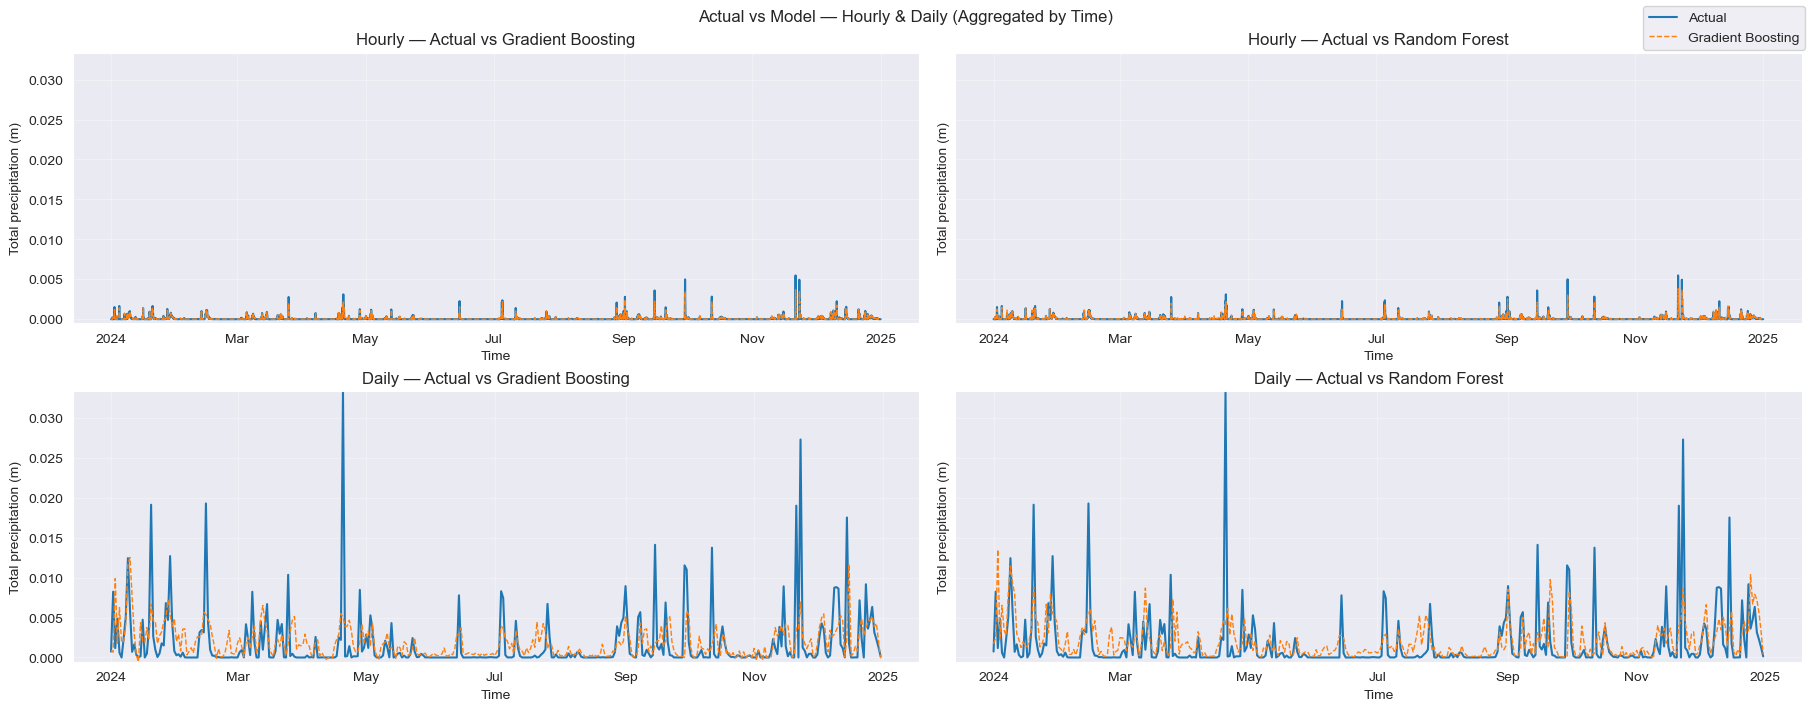

In [21]:
# === Next Cell: Grid the same "Actual vs Model" plots for HOURLY & DAILY — no retrain ===
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# -------- options you can tweak --------
MODEL_LIST = None          # None = all model columns found; or e.g. ["Random Forest","Gradient Boosting"]
CONVERT_TO_KG_M2 = False   # True => multiply series by 1000 and label as kg/m² (≈ mm)
SHARE_Y_WITHIN_ROW = True  # share y-axis among models within each row (hourly row & daily row)
# --------------------------------------

def _load_pred_df(granularity="hourly"):
    """
    Returns DataFrame with columns:
    ['valid_time','latitude','longitude','actual', <model cols>]
    Prefers in-memory objects; falls back to CSV written by the first cell.
    """
    if granularity == "hourly" and "test_pred_hr" in globals():
        df = test_pred_hr.copy()
    elif granularity == "daily" and "test_pred_d" in globals():
        df = test_pred_d.copy()
    else:
        try:
            path = pred_hourly_path if granularity == "hourly" else pred_daily_path
        except NameError:
            fname = "predictions_hourly_test_2024plus.csv" if granularity == "hourly" else "predictions_daily_test_2024plus.csv"
            path = os.path.join(OUT_DIR, fname)
        if not os.path.exists(path):
            raise FileNotFoundError(f"Cannot find {granularity} predictions at:\n{path}\nRun the training cell once.")
        df = pd.read_csv(path, parse_dates=["valid_time"])

    if "actual" not in df.columns and "tp" in df.columns:
        df = df.rename(columns={"tp":"actual"})
    if not np.issubdtype(df["valid_time"].dtype, np.datetime64):
        df["valid_time"] = pd.to_datetime(df["valid_time"], errors="coerce")
    return df

def _get_model_cols(df):
    base = {"valid_time","latitude","longitude","actual","Season"}
    # numeric model columns only
    return [c for c in df.columns if c not in base and pd.api.types.is_numeric_dtype(df[c])]

def _agg_timeseries(df, cols):
    # average across lat/lon grid per timestamp
    keep = ["actual"] + cols
    return df.groupby("valid_time")[keep].mean(numeric_only=True).sort_index()

# Load
df_h = _load_pred_df("hourly")
df_d = _load_pred_df("daily")

# Choose models
models_h = _get_model_cols(df_h)
models_d = _get_model_cols(df_d)
models = sorted(set(models_h).union(models_d)) if MODEL_LIST is None else [m for m in MODEL_LIST if (m in models_h or m in models_d)]
if not models:
    raise ValueError("No model columns found to plot.")

# Optional units
unit_label = "Total precipitation (m)"
if CONVERT_TO_KG_M2:
    unit_label = "Total precipitation (kg/m²)"
    for df_ in (df_h, df_d):
        df_["actual"] = df_["actual"] * 1000.0
        for m in _get_model_cols(df_):
            df_[m] = df_[m] * 1000.0

# Aggregate time series once
agg_h = _agg_timeseries(df_h, [m for m in models if m in df_h.columns])
agg_d = _agg_timeseries(df_d, [m for m in models if m in df_d.columns])

# Build figure: rows = [hourly, daily], cols = len(models)
ncols = len(models)
fig, axes = plt.subplots(2, ncols, figsize=(9*ncols, 7), sharey=SHARE_Y_WITHIN_ROW, constrained_layout=True)
if ncols == 1:  # make indexing consistent when only one model
    axes = np.array(axes).reshape(2, 1)

# y-limits per row (optional shared y within the row)
def _row_limits(agg_df, cols):
    if not SHARE_Y_WITHIN_ROW:
        return (None, None)
    ymins, ymaxs = [], []
    for m in cols:
        if m in agg_df.columns and not agg_df[m].empty:
            ymins.append(np.nanmin([agg_df["actual"].min(), agg_df[m].min()]))
            ymaxs.append(np.nanmax([agg_df["actual"].max(), agg_df[m].max()]))
    return (np.nanmin(ymins), np.nanmax(ymaxs)) if ymins and ymaxs else (None, None)

ymin_h, ymax_h = _row_limits(agg_h, models)
ymin_d, ymax_d = _row_limits(agg_d, models)

for j, m in enumerate(models):
    # --- Hourly (top row) ---
    ax = axes[0, j]
    ax.set_title(f"Hourly — Actual vs {m}")
    ax.set_xlabel("Time"); ax.set_ylabel(unit_label); ax.grid(alpha=0.3)
    if m in agg_h.columns:
        ax.plot(agg_h.index, agg_h["actual"], label="Actual", linewidth=1.5)
        ax.plot(agg_h.index, agg_h[m], linestyle="--", label=m, linewidth=1.0)
        if ymin_h is not None and ymax_h is not None:
            ax.set_ylim(ymin_h, ymax_h)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    else:
        ax.text(0.5, 0.5, "No hourly data for this model", ha="center", va="center")

    # --- Daily (bottom row) ---
    ax = axes[1, j]
    ax.set_title(f"Daily — Actual vs {m}")
    ax.set_xlabel("Time"); ax.set_ylabel(unit_label); ax.grid(alpha=0.3)
    if m in agg_d.columns:
        ax.plot(agg_d.index, agg_d["actual"], label="Actual", linewidth=1.5)
        ax.plot(agg_d.index, agg_d[m], linestyle="--", label=m, linewidth=1.0)
        if ymin_d is not None and ymax_d is not None:
            ax.set_ylim(ymin_d, ymax_d)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    else:
        ax.text(0.5, 0.5, "No daily data for this model", ha="center", va="center")

# one legend for the whole figure (from first valid axis)
for ax in axes.ravel():
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")
        break

fig.suptitle("Actual vs Model — Hourly & Daily (Aggregated by Time)")
plt.show()


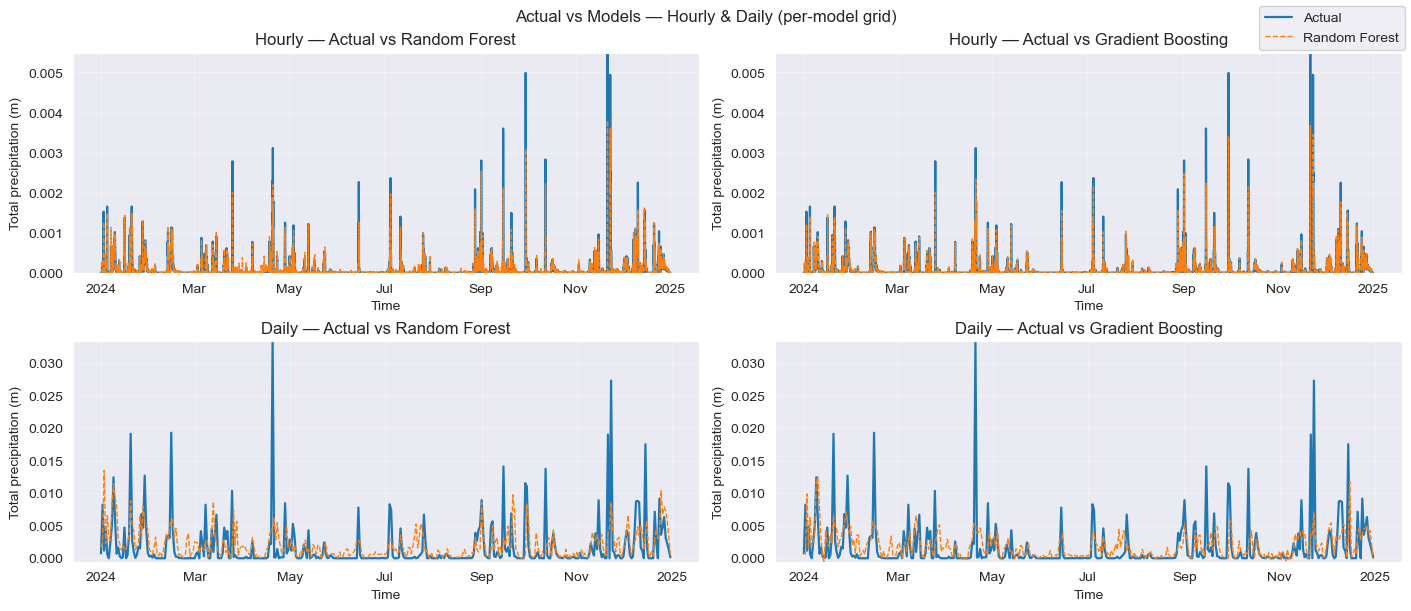

In [23]:
# === Next Cell: Grid per-model plots only (Hourly row, Daily row) — no retrain ===
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---- options ----
CONVERT_TO_KG_M2 = False    # True => multiply by 1000 and label as kg/m² (≈ mm)
MODEL_LIST = None           # None = all models found, or e.g. ["Random Forest","Gradient Boosting"]
SHARE_Y_WITHIN_ROW = True   # share y-scale across models within each row
# ------------------

def _load_pred_df(kind):
    # prefer in-memory from your first cell
    if kind == "hourly" and "test_pred_hr" in globals():
        df = test_pred_hr.copy()
    elif kind == "daily" and "test_pred_d" in globals():
        df = test_pred_d.copy()
    else:
        # fallback to CSVs the first cell saved
        try:
            path = pred_hourly_path if kind == "hourly" else pred_daily_path
        except NameError:
            fname = "predictions_hourly_test_2024plus.csv" if kind == "hourly" else "predictions_daily_test_2024plus.csv"
            path = os.path.join(OUT_DIR, fname)
        df = pd.read_csv(path, parse_dates=["valid_time"])
    if "actual" not in df.columns and "tp" in df.columns:
        df = df.rename(columns={"tp":"actual"})
    if not np.issubdtype(df["valid_time"].dtype, np.datetime64):
        df["valid_time"] = pd.to_datetime(df["valid_time"], errors="coerce")
    return df

def _model_cols(df):
    base = {"valid_time","latitude","longitude","actual","Season"}
    return [c for c in df.columns if c not in base and pd.api.types.is_numeric_dtype(df[c])]

def _agg(df, models):
    keep = ["actual"] + [m for m in models if m in df.columns]
    return df.groupby("valid_time")[keep].mean(numeric_only=True).sort_index()

# Load predictions
df_h = _load_pred_df("hourly")
df_d = _load_pred_df("daily")

# Decide model order (prefer MODELS keys for consistency)
if "MODELS" in globals() and isinstance(MODELS, dict):
    all_found = set(_model_cols(df_h)).union(_model_cols(df_d))
    models = [m for m in MODELS.keys() if m in all_found]
else:
    models = sorted(set(_model_cols(df_h)).union(_model_cols(df_d)))

if MODEL_LIST:
    models = [m for m in MODEL_LIST if m in models]
if not models:
    raise ValueError("No model prediction columns found to plot.")

# Optional unit conversion
unit_label = "Total precipitation (m)"
if CONVERT_TO_KG_M2:
    unit_label = "Total precipitation (kg/m²)"
    for df_ in (df_h, df_d):
        df_["actual"] = df_["actual"] * 1000.0
        for m in _model_cols(df_):
            df_[m] = df_[m] * 1000.0

# Aggregate across grid per timestamp (same as first script)
agg_hr = _agg(df_h, models)
agg_d  = _agg(df_d, models)

# Build figure: rows = [hourly, daily], cols = one per model
ncols = len(models)
fig, axes = plt.subplots(2, ncols, figsize=(7*ncols, 6), sharey=False, constrained_layout=True)
if ncols == 1:
    axes = np.array(axes).reshape(2, 1)

def _row_limits(agg_df):
    if not SHARE_Y_WITHIN_ROW:
        return (None, None)
    ymins, ymaxs = [agg_df["actual"].min()], [agg_df["actual"].max()]
    for m in models:
        if m in agg_df.columns and not agg_df[m].empty:
            ymins.append(agg_df[m].min())
            ymaxs.append(agg_df[m].max())
    return (np.nanmin(ymins), np.nanmax(ymaxs))

ymin_h, ymax_h = _row_limits(agg_hr)
ymin_d, ymax_d = _row_limits(agg_d)

def _fmt(ax):
    ax.grid(alpha=0.3)
    ax.set_xlabel("Time")
    ax.set_ylabel(unit_label)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

# Plot
for j, m in enumerate(models):
    # Hourly row
    ax = axes[0, j]
    ax.set_title(f"Hourly — Actual vs {m}")
    ax.plot(agg_hr.index, agg_hr["actual"], label="Actual", linewidth=1.6)
    if m in agg_hr.columns:
        ax.plot(agg_hr.index, agg_hr[m], linestyle="--", linewidth=1.0, label=m)
    if ymin_h is not None and ymax_h is not None:
        ax.set_ylim(ymin_h, ymax_h)
    _fmt(ax)

    # Daily row
    ax = axes[1, j]
    ax.set_title(f"Daily — Actual vs {m}")
    ax.plot(agg_d.index, agg_d["actual"], label="Actual", linewidth=1.6)
    if m in agg_d.columns:
        ax.plot(agg_d.index, agg_d[m], linestyle="--", linewidth=1.0, label=m)
    if ymin_d is not None and ymax_d is not None:
        ax.set_ylim(ymin_d, ymax_d)
    _fmt(ax)

# Global legend (take from first populated axis)
for ax in axes.ravel():
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")
        break

fig.suptitle("Actual vs Models — Hourly & Daily (per-model grid)")
plt.show()
